In [42]:
import pandas as pd

data = pd.read_csv("data/raw/medical_cost.csv")
data.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [7]:
data.info()
data.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [8]:
data.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [ ]:
data["smoker"].value_counts()

region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64

In [12]:
data.duplicated().sum()

np.int64(1)

In [43]:

data['sex'] = data['sex'].map({'male': 1, 'female': 0})

In [44]:
data['smoker'] = data['smoker'].map({'yes': 1, 'no': 0})

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

<Axes: xlabel='bmi', ylabel='charges'>

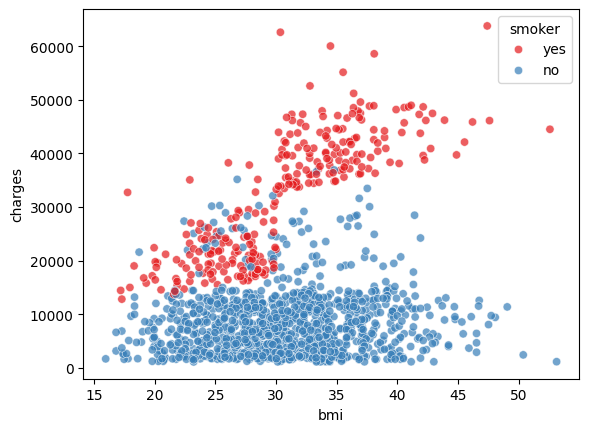

In [ ]:
sns.scatterplot(
    data=data, 
    x='bmi', 
    y='charges', 
    hue='smoker',     
    alpha=0.7,        
    palette='Set1'    
)

WE can clearly see the correlation between the smoking status of an individual and the charges of the insurance, 

<Axes: ylabel='charges'>

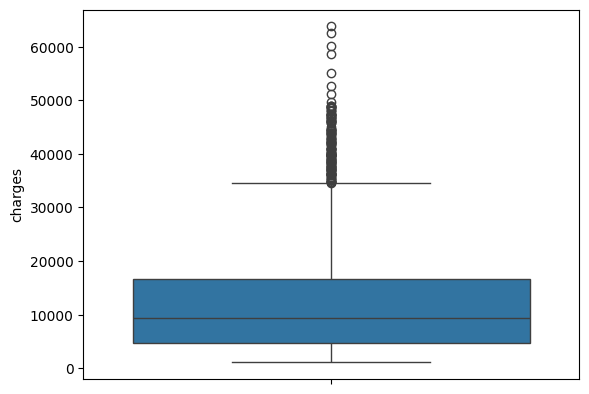

In [24]:
sns.boxplot(data=data, y='charges')

We can clearly see the outliers, despite the 50th percentile sitting below 20k dollars a year in charges, the median sits way higher at >30K $

/var/folders/4x/8yhzr1y14ld556ngskgq54000000gn/T/ipykernel_70325/704598295.py:1: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(


<Axes: xlabel='age', ylabel='charges'>

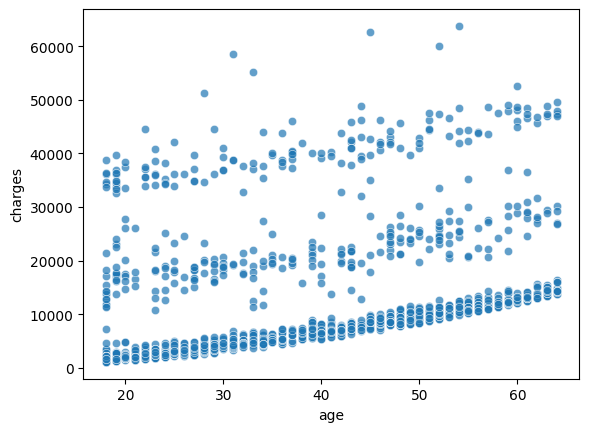

In [ ]:
sns.scatterplot(
    data=data, 
    x='age', 
    y='charges',    
    alpha=0.7,        
    palette='Set1'    
)


In [48]:
data["region"] = data['region'].map({'southwest': 1, 'southeast': 0, 'northwest':2, 'northeast':3})


<Axes: >

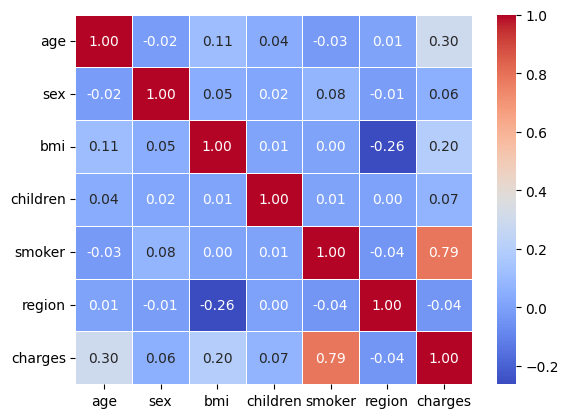

In [ ]:
numeric_data = data.select_dtypes(include=['number'])
correlation_matrix = numeric_data.corr()


sns.heatmap(
    correlation_matrix, 
    annot=True,        
    cmap='coolwarm',   
    fmt='.2f',         
    linewidths=0.5     
)

This confirms earlier speculations, as smoking, age and BMI are the leading variables that control the charge's outcome

In [50]:
data['smoker_age'] = (data['smoker'] == 1) * data['age']

In [51]:
data['smoker_high_bmi'] = ((data['smoker'] == 1) & (data['bmi'] >= 30)).astype(int)

In [52]:
data.to_csv('data/processed/clean_insurance.csv', index=False)